# Pipeline de análise de imagens de RX normal, pneumonia ou COVID19 visando emissão de laudos / diagnóstico automatizados a serem confirmados pelo profissional de medicina

### Rede Neural VGG16

In [47]:
import glob
import shutil
import cv2
import os
from PIL import Image
import seaborn as sns
import numpy as np
from matplotlib import pyplot as plt
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import *
from tensorflow.keras.preprocessing import *
from keras.applications.vgg16 import VGG16
from keras import layers
# from skimage.feature import local_binary_pattern

import warnings
# Ignorar warnings
warnings.filterwarnings('ignore')

In [48]:
name_list = glob.glob('dataset/NORMAL/*')

labels = ['NORMAL', 'COVID', 'PNEUMONIA']

# Carregando as imagens de treinamento e seus rótulos
X= []
y = []

for name in name_list:
  y.append(0)
  img = cv2.imread(name)
  img = tf.keras.preprocessing.image.img_to_array(img)
  img = cv2.resize(img,(100,100))
  X.append((img))
len(X)

1802

In [49]:
name_list = glob.glob('dataset/COVID/*')

for name in name_list:
  y.append(1)
  img = cv2.imread(name)
  img = tf.keras.preprocessing.image.img_to_array(img)
  img = cv2.resize(img,(100,100))
  X.append((img))
len(X)

3428

In [50]:
name_list = glob.glob('dataset/PNEUMONIA/*')

for name in name_list:
  y.append(2)
  img = cv2.imread(name)
  img = tf.keras.preprocessing.image.img_to_array(img)
  img = cv2.resize(img,(100,100))
  X.append((img))
len(X)

5228

In [51]:
X = np.array(X)
y = np.array(y).reshape(-1,1)

In [52]:
print(len(X))
print(X.shape)
print(y.shape)

5228
(5228, 100, 100, 3)
(5228, 1)


In [53]:
from sklearn.model_selection import train_test_split
# Divide o conjunto de dados em 80% de conjunto de treinamento e 20% de conjunto de teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Divida o conjunto de dados de teste em 50% do conjunto de validação e 50% do conjunto de teste
X_test, X_val, y_test, y_val = train_test_split(X_test, y_test, test_size=0.2, random_state=42)

# Imprime informações sobre o tamanho dos conjuntos de dados
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(4182, 100, 100, 3)
(210, 100, 100, 3)
(836, 100, 100, 3)


In [54]:
X_train = X_train / 255
X_test = X_test / 255
X_val = X_val / 255

In [55]:
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(100,100, 3))

# Congela os pisos do modelo VGG16
for layer in base_model.layers:
    layer.trainable = False

model = Sequential()
model.add(base_model)
model.add(Flatten())
model.add(Dense(1024))
model.add(Activation("relu"))
model.add(Dense(512))
model.add(Activation("relu"))
model.add(Dense(3))
model.add(Activation("softmax"))
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1024)           │     4,719,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │         1,539 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 3)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,960,643 (76.14 MB)

 Trainable params: 5,245,955 (20.01 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [56]:
%%time
learning_rate = 0.0001 # Taxa de aprendizado inicial
decay_steps = 10       # Número de épocas para aplicar o decaimento
decay_rate = 1         # Taxa de redução da taxa de aprendizado

# Inicializa o escalonador de taxa de aprendizado
lr_scheduler = tf.keras.optimizers.schedules.ExponentialDecay(learning_rate, decay_steps, decay_rate)
optimizer1 = tf.keras.optimizers.Adam(learning_rate = lr_scheduler)
model.compile(
    optimizer=optimizer1,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(X_train, y_train, batch_size = 32, epochs = 5, validation_data = (X_val, y_val))

Epoch 1/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 81s 608ms/step - accuracy: 0.9218 - loss: 0.2440 - val_accuracy: 0.9333 - val_loss: 0.1766
Epoch 2/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 82s 624ms/step - accuracy: 0.9567 - loss: 0.1231 - val_accuracy: 0.9571 - val_loss: 0.1170
Epoch 3/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 82s 625ms/step - accuracy: 0.9680 - loss: 0.0953 - val_accuracy: 0.9476 - val_loss: 0.1359
Epoch 4/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 90s 688ms/step - accuracy: 0.9742 - loss: 0.0761 - val_accuracy: 0.9476 - val_loss: 0.1235
Epoch 5/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 86s 658ms/step - accuracy: 0.9794 - loss: 0.0591 - val_accuracy: 0.9619 - val_loss: 0.0979
CPU times: total: 44min 47s
Wall time: 7min 1s


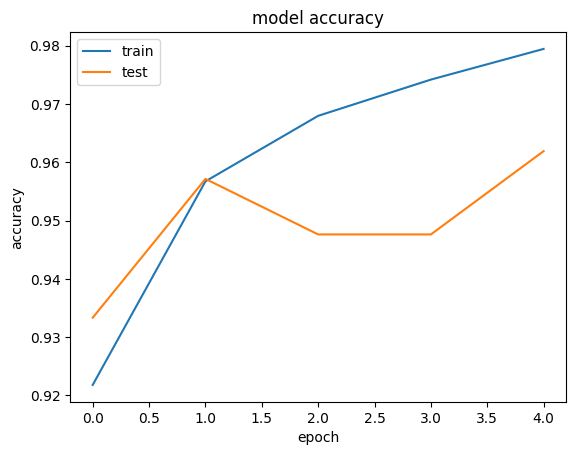

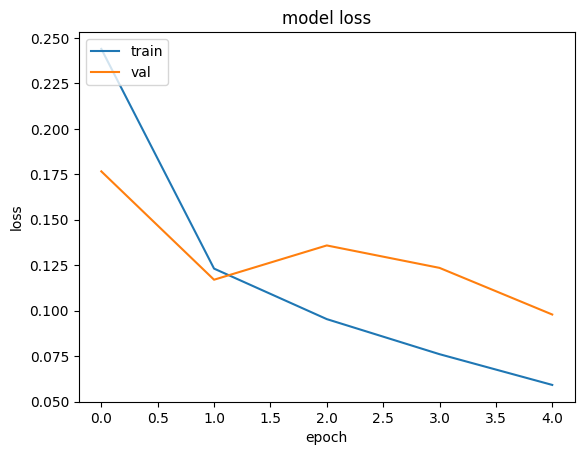

In [57]:
from matplotlib import pyplot  as plt

# Resumo das acurácias
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train','test'],loc ='upper left')
plt.show()

# Resumo das perdas
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train','val'],loc ='upper left')
plt.show()

In [58]:
model.save('model1.keras')

In [59]:
model1 = load_model('model1.keras')

In [60]:
test_loss, test_accuracy = model1.evaluate(X_test, y_test, verbose=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.1071
Test Accuracy: 0.9701


27/27 ━━━━━━━━━━━━━━━━━━━━ 17s 592ms/step
Accuracy: 0.9701
              precision    recall  f1-score   support

      Normal       0.95      0.99      0.97       312
       Covid       0.98      0.99      0.99       243
   Pneumonia       0.99      0.94      0.96       281

    accuracy                           0.97       836
   macro avg       0.97      0.97      0.97       836
weighted avg       0.97      0.97      0.97       836



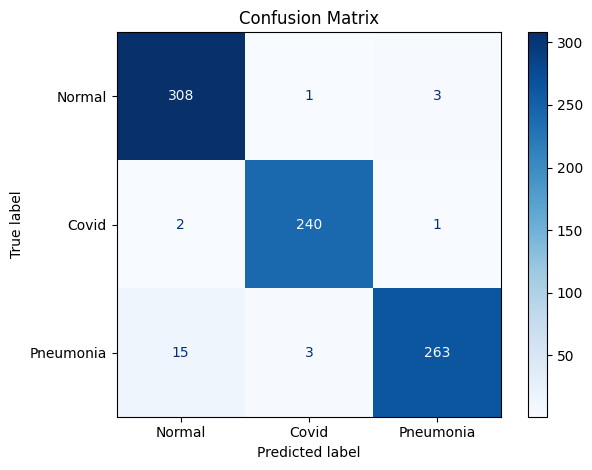

In [61]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Previsões
y_hat = model1.predict(X_test)

# Converte as probabilidades para as classes 0, 1 e 2
y_pred = np.argmax(y_hat, axis=1)

# Transforma y_test de (n, 1) para (n,)
y_true = y_test.reshape(-1)

# Nomes corretos conforme os rótulos usados na criação do dataset:
# 0 = NORMAL
# 1 = COVID
# 2 = PNEUMONIA
class_names = ['Normal', 'Covid', 'Pneumonia']

accuracy = accuracy_score(y_true, y_pred)
print(f"Accuracy: {accuracy:.4f}")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=class_names
    )
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap='Blues',
    values_format='d'
)

plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()